# Online Advertising Performance — Project Walkthrough

**Finlatics Data Science Work Experience Program** · dataset: `online_advertising_performance_data.csv`

This notebook walks through the project end to end using the project's own modules (`analysis/`, `models/`), so every number matches `python main.py`, the API and the dashboard.

**Two businesses are in the data:**
- *Company X* (advertiser) pays **`revenue`** to *Advert Firm A* and receives attributed **`post_click_sales_amount`**.
- *Advert Firm A* pays publishers **`cost`** and keeps **margin = revenue − cost**.

Written reports: [`reports/eda_findings.md`](../reports/eda_findings.md) and [`reports/model_report.md`](../reports/model_report.md).

In [1]:
import os, sys
from pathlib import Path

os.environ["LOG_LEVEL"] = "WARNING"           # keep pipeline logs out of the outputs
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
FIGURES = PROJECT_ROOT / "reports" / "figures"

## 1. Data understanding

In [2]:
from analysis.data_loader import load_data, inspect_data

raw = load_data()
raw.head()

Loaded 15408 rows × 12 columns from online_advertising_performance_data.csv (dropped 2 empty columns)


,month,day,campaign_number,user_engagement,banner,placement,displays,cost,clicks,revenue,post_click_conversions,post_click_sales_amount
0,April,1,camp 1,High,160 x 600,abc,4,0.0060,0,0.0000,0,0.0000
1,April,1,camp 1,High,160 x 600,def,20170,26.7824,158,28.9717,23,1972.4602
2,April,1,camp 1,High,160 x 600,ghi,14701,27.6304,158,28.9771,78,2497.2636
3,April,1,camp 1,High,160 x 600,mno,171259,216.8750,1796,329.4518,617,24625.3234
4,April,1,camp 1,Low,160 x 600,def,552,0.0670,1,0.1834,0,0.0000


In [3]:
summary = inspect_data(raw)


DATA INSPECTION REPORT
Shape: 15408 rows × 12 columns
Exact duplicate rows: 5

Missing Values:
  placement: 413 (2.68%)

Category Levels:
  month (3): April, May, June
  campaign_number (3): camp 3, camp 1, camp 2
  user_engagement (3): Medium, Low, High
  banner (8): 728 x 90, 300 x 250, 240 x 400, 670 x 90, 468 x 60, 160 x 600, 580 x 400, 800 x 250
  placement (6): mno, def, ghi, jkl, abc, nan

Data Types:
  month: str
  day: int64
  campaign_number: str
  user_engagement: str
  banner: str
  placement: str
  displays: int64
  cost: float64
  clicks: int64
  revenue: float64
  post_click_conversions: int64
  post_click_sales_amount: float64


## 2. Cleaning

- Empty export columns dropped
- 413 missing placements → `Unknown` (they carry real cost)
- 5 exact duplicates removed
- Date built from month + day (year 2020)
- Suspicious rows **flagged, not dropped**

In [4]:
from analysis.data_cleaning import clean_data

df, report = clean_data(raw, return_report=True)
report


DATA CLEANING PIPELINE
[1/6] Standardized categorical values
    -> placement: filled 413 nulls with 'Unknown'
[2/6] Handled missing values
[3/6] Removed 5 exact duplicate rows
[4/6] Built date column (2020-04-01 to 2020-06-30)
[5/6] Validated numeric columns
    -> flag_clicks_gt_displays: 2 rows (kept, flagged)
    -> flag_conv_gt_clicks: 328 rows (kept, flagged)
    -> flag_conv_without_clicks: 31 rows (kept, flagged)
[6/6] Added data-quality flags

Cleaning complete: 15408 -> 15403 rows (5 removed)


{'initial_rows': 15408,
 'missing_placement_filled': 413,
 'duplicates_removed': 5,
 'flags': {'flag_clicks_gt_displays': 2,
  'flag_conv_gt_clicks': 328,
  'flag_conv_without_clicks': 31},
 'grain_duplicates': 0,
 'final_rows': 15403}

## 3. KPIs

Grouped rates are ratio-of-totals; a zero denominator gives NaN, not 0.

In [5]:
from analysis.metrics import compute_kpis, summarize_by, get_overall_summary

df = compute_kpis(df)
overall = get_overall_summary(df, verbose=False)
pd.Series(overall).to_frame("value")


Computed 10 KPI columns: firm_margin, ctr, cpm, conversion_rate, firm_cpc, firm_roi, advertiser_cpc, advertiser_cpa, advertiser_roas, avg_order_value


,value
total_records,15403
date_range,2020-04-01 to 2020-06-30
days,91
campaigns,3
banners,8
placements,6
total_displays,239014261
total_clicks,2492825
total_cost,175192.22
total_revenue,276262.62


In [6]:
cols = ["revenue", "cost", "firm_margin", "firm_roi", "ctr", "conversion_rate",
        "advertiser_roas", "active_days", "revenue_share"]
summarize_by(df, "campaign_number")[cols].round(4)

,revenue,cost,firm_margin,firm_roi,ctr,conversion_rate,advertiser_roas,active_days,revenue_share
campaign_number,,,,,,,,,
camp 1,230533.5216,150688.1225,79845.3991,0.5299,0.0098,0.4493,134.5255,91,0.8345
camp 2,34890.4153,17037.3496,17853.0657,1.0479,0.0194,0.0156,33.4622,30,0.1263
camp 3,10838.6790,7466.7479,3371.9311,0.4516,0.0040,0.0243,49.3840,91,0.0392


In [7]:
summarize_by(df, "banner")[cols].round(4)

,revenue,cost,firm_margin,firm_roi,ctr,conversion_rate,advertiser_roas,active_days,revenue_share
banner,,,,,,,,,
240 x 400,129930.1349,56415.2964,73514.8385,1.3031,0.0169,0.2424,104.6071,91,0.4703
728 x 90,64342.1614,52830.4397,11511.7217,0.2179,0.0075,0.2991,126.8715,91,0.2329
300 x 250,43171.3532,35438.5266,7732.8266,0.2182,0.0075,0.2913,147.7613,91,0.1563
160 x 600,23514.2945,17516.0036,5998.2909,0.3424,0.0083,0.2036,102.2835,76,0.0851
580 x 400,11193.1428,8978.5730,2214.5698,0.2467,0.0168,0.2632,146.0067,91,0.0405
670 x 90,4022.8618,3817.9569,204.9049,0.0537,0.0068,0.2854,127.8194,91,0.0146
468 x 60,87.5847,192.6514,-105.0667,-0.5454,0.0019,0.4247,317.9065,91,0.0003
800 x 250,1.0826,2.7724,-1.6898,-0.6095,0.0057,0.2500,103.7161,91,0.0000


In [8]:
summarize_by(df, "placement")[cols].round(4)

,revenue,cost,firm_margin,firm_roi,ctr,conversion_rate,advertiser_roas,active_days,revenue_share
placement,,,,,,,,,
ghi,151548.1020,62218.5788,89329.5232,1.4357,0.0209,0.2703,108.5382,91,0.5486
mno,100458.3451,95006.2425,5452.1026,0.0574,0.0069,0.2650,135.0218,91,0.3636
def,15861.1241,14207.6762,1653.4479,0.1164,0.0062,0.1695,99.4754,91,0.0574
jkl,8254.4889,3629.5653,4624.9236,1.2742,0.0098,0.2778,131.0646,91,0.0299
abc,140.2604,127.3760,12.8844,0.1012,0.0065,0.5202,304.6300,91,0.0005
Unknown,0.2954,2.7812,-2.4858,-0.8938,0.0016,0.4000,640.3443,84,0.0000


## 4. Exploratory data analysis

The Finlatics problem statement asks 20 questions. `reports/eda_findings.md` answers each one (Q1–Q20) with a chart; all 19 charts are regenerated below into `reports/figures/`, and a few are shown here.

In [9]:
from analysis.visualizations import generate_all_charts

saved = generate_all_charts(df, FIGURES)

  [OK] Saved: 01_daily_trends.png


  [OK] Saved: 02_monthly_by_campaign.png


  [OK] Saved: 03_engagement_trends.png


  [OK] Saved: 04_banner_performance.png


  [OK] Saved: 05_placement_performance.png


  [OK] Saved: 06_cost_vs_revenue.png


... (9 outputs left out)

  [OK] Saved: 16_cost_per_click_and_conversion.png


  [OK] Saved: 17_segment_effectiveness.png


  [OK] Saved: 18_roi_consistency.png


  [OK] Saved: 19_weekday_vs_weekend_engagement.png


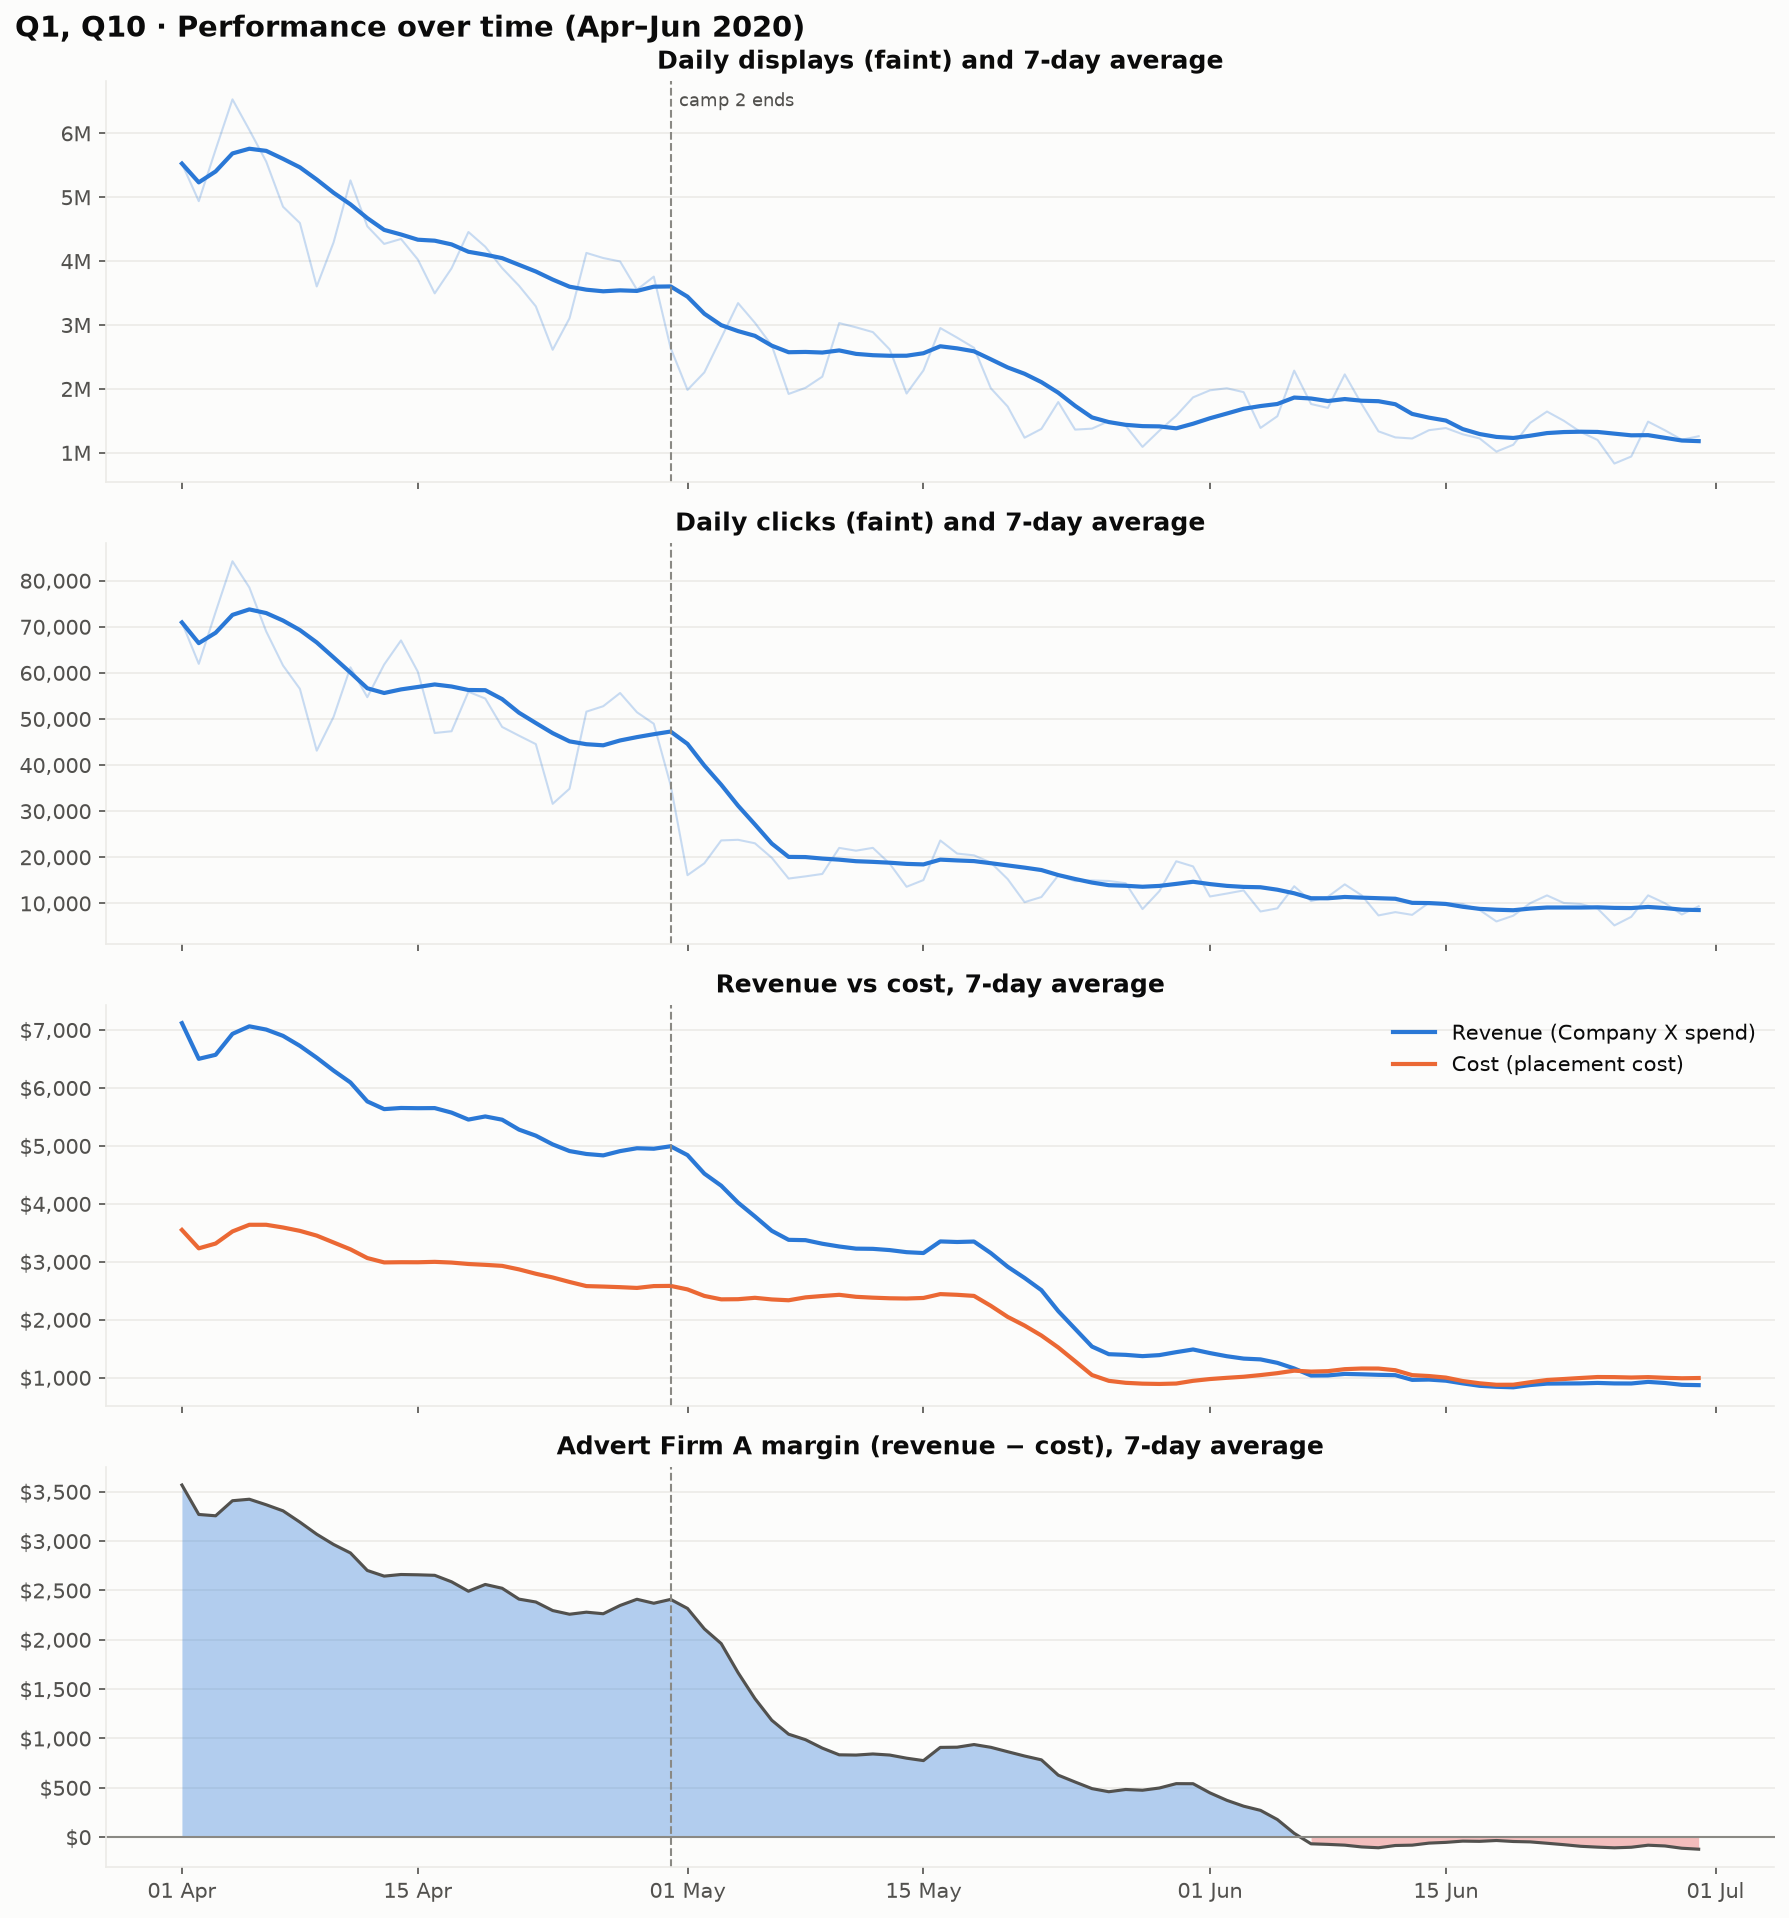

In [10]:
display(Image(filename=FIGURES / "01_daily_trends.png", width=900))

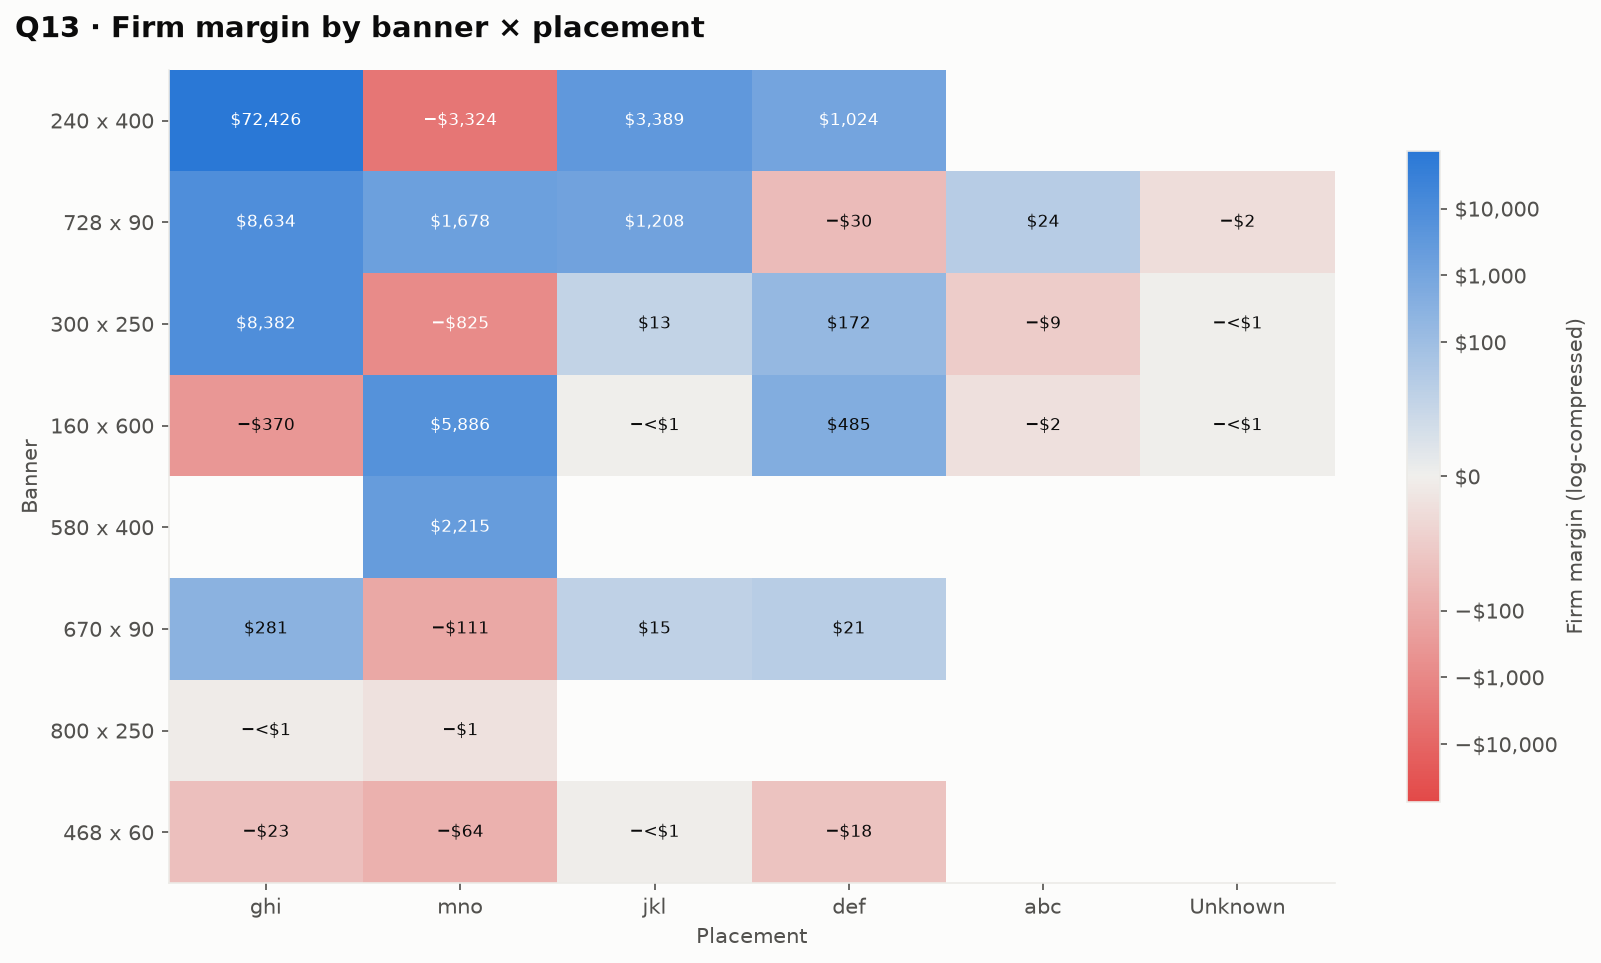

In [11]:
display(Image(filename=FIGURES / "09_banner_placement_margin.png", width=800))

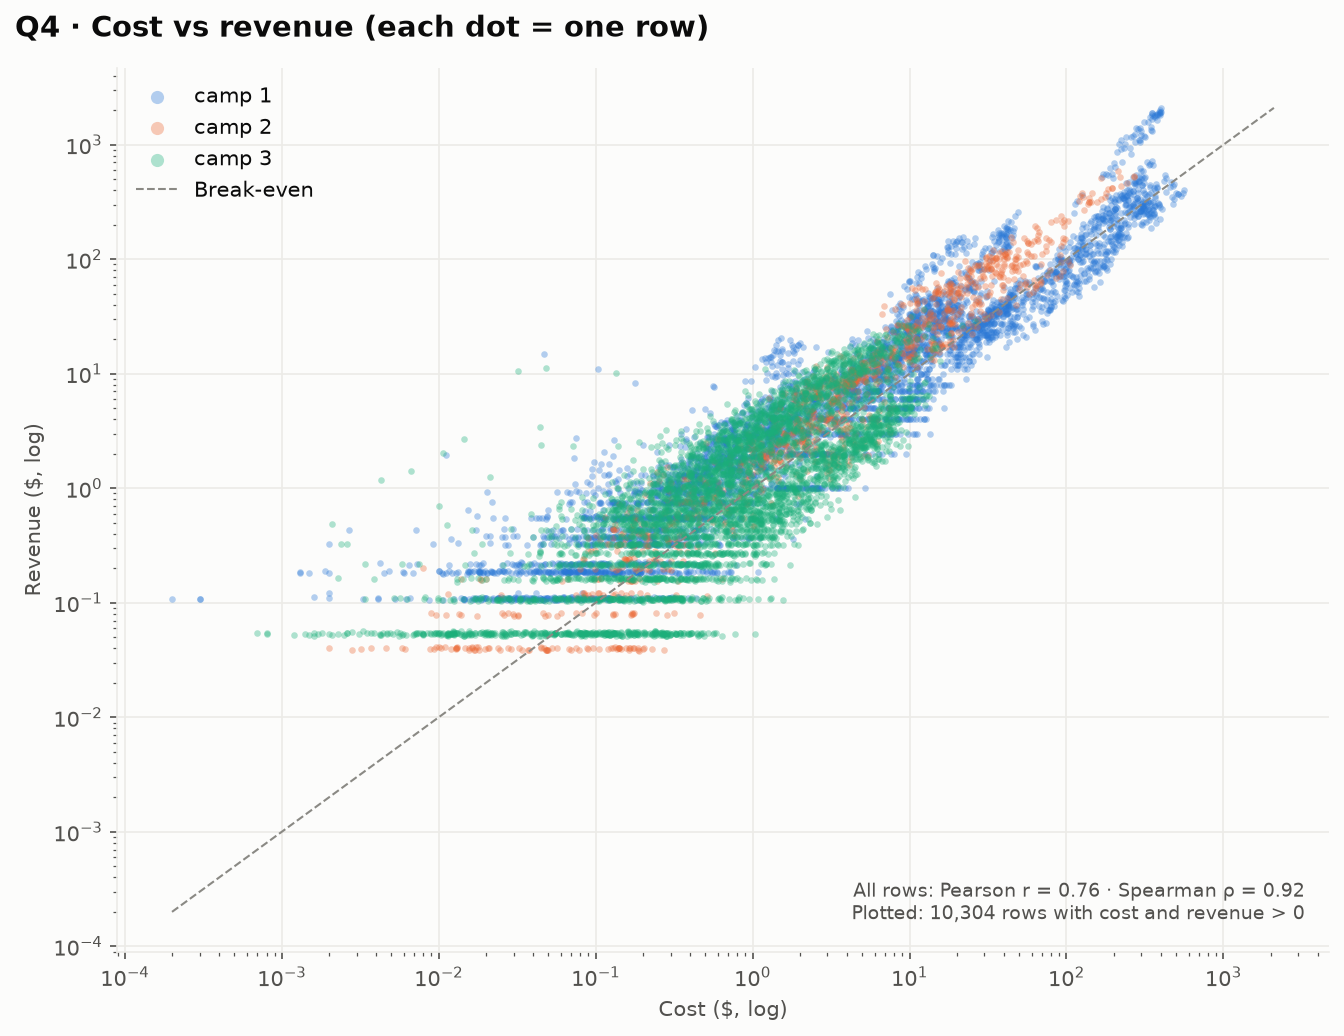

In [12]:
display(Image(filename=FIGURES / "06_cost_vs_revenue.png", width=650))

Q5, Q17, Q18: what Company X pays per click and per conversion.

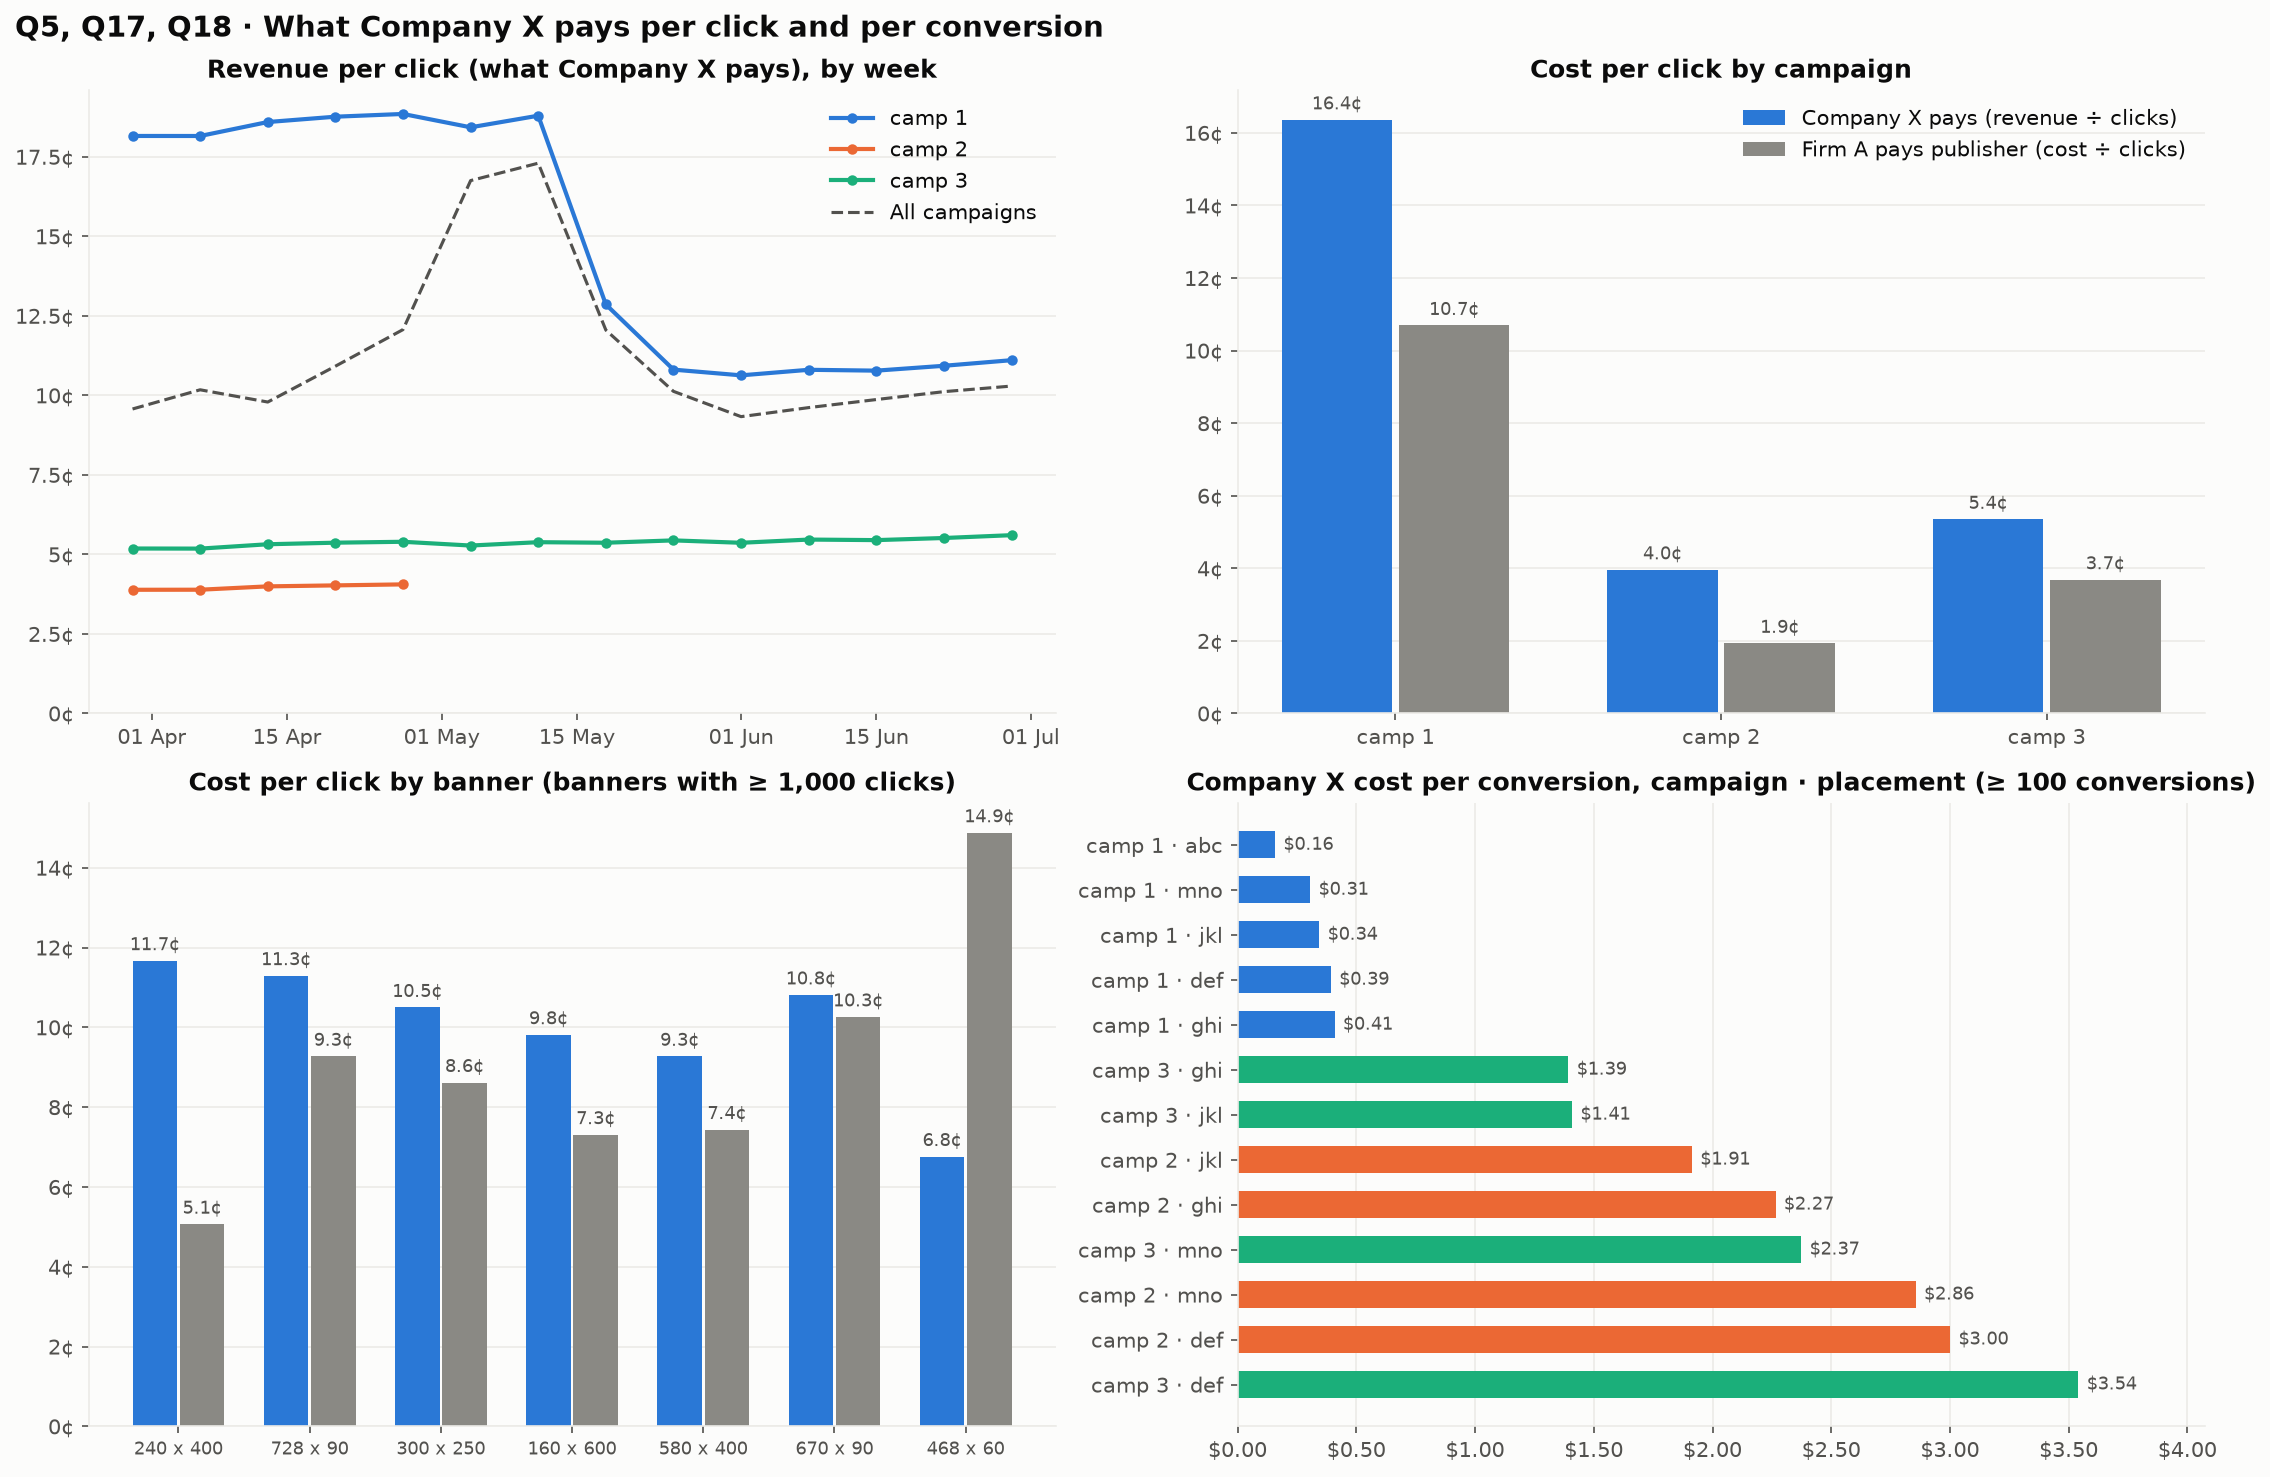

In [13]:
display(Image(filename=FIGURES / "16_cost_per_click_and_conversion.png", width=900))

Q14: which banners and campaigns keep a positive ROI over time.

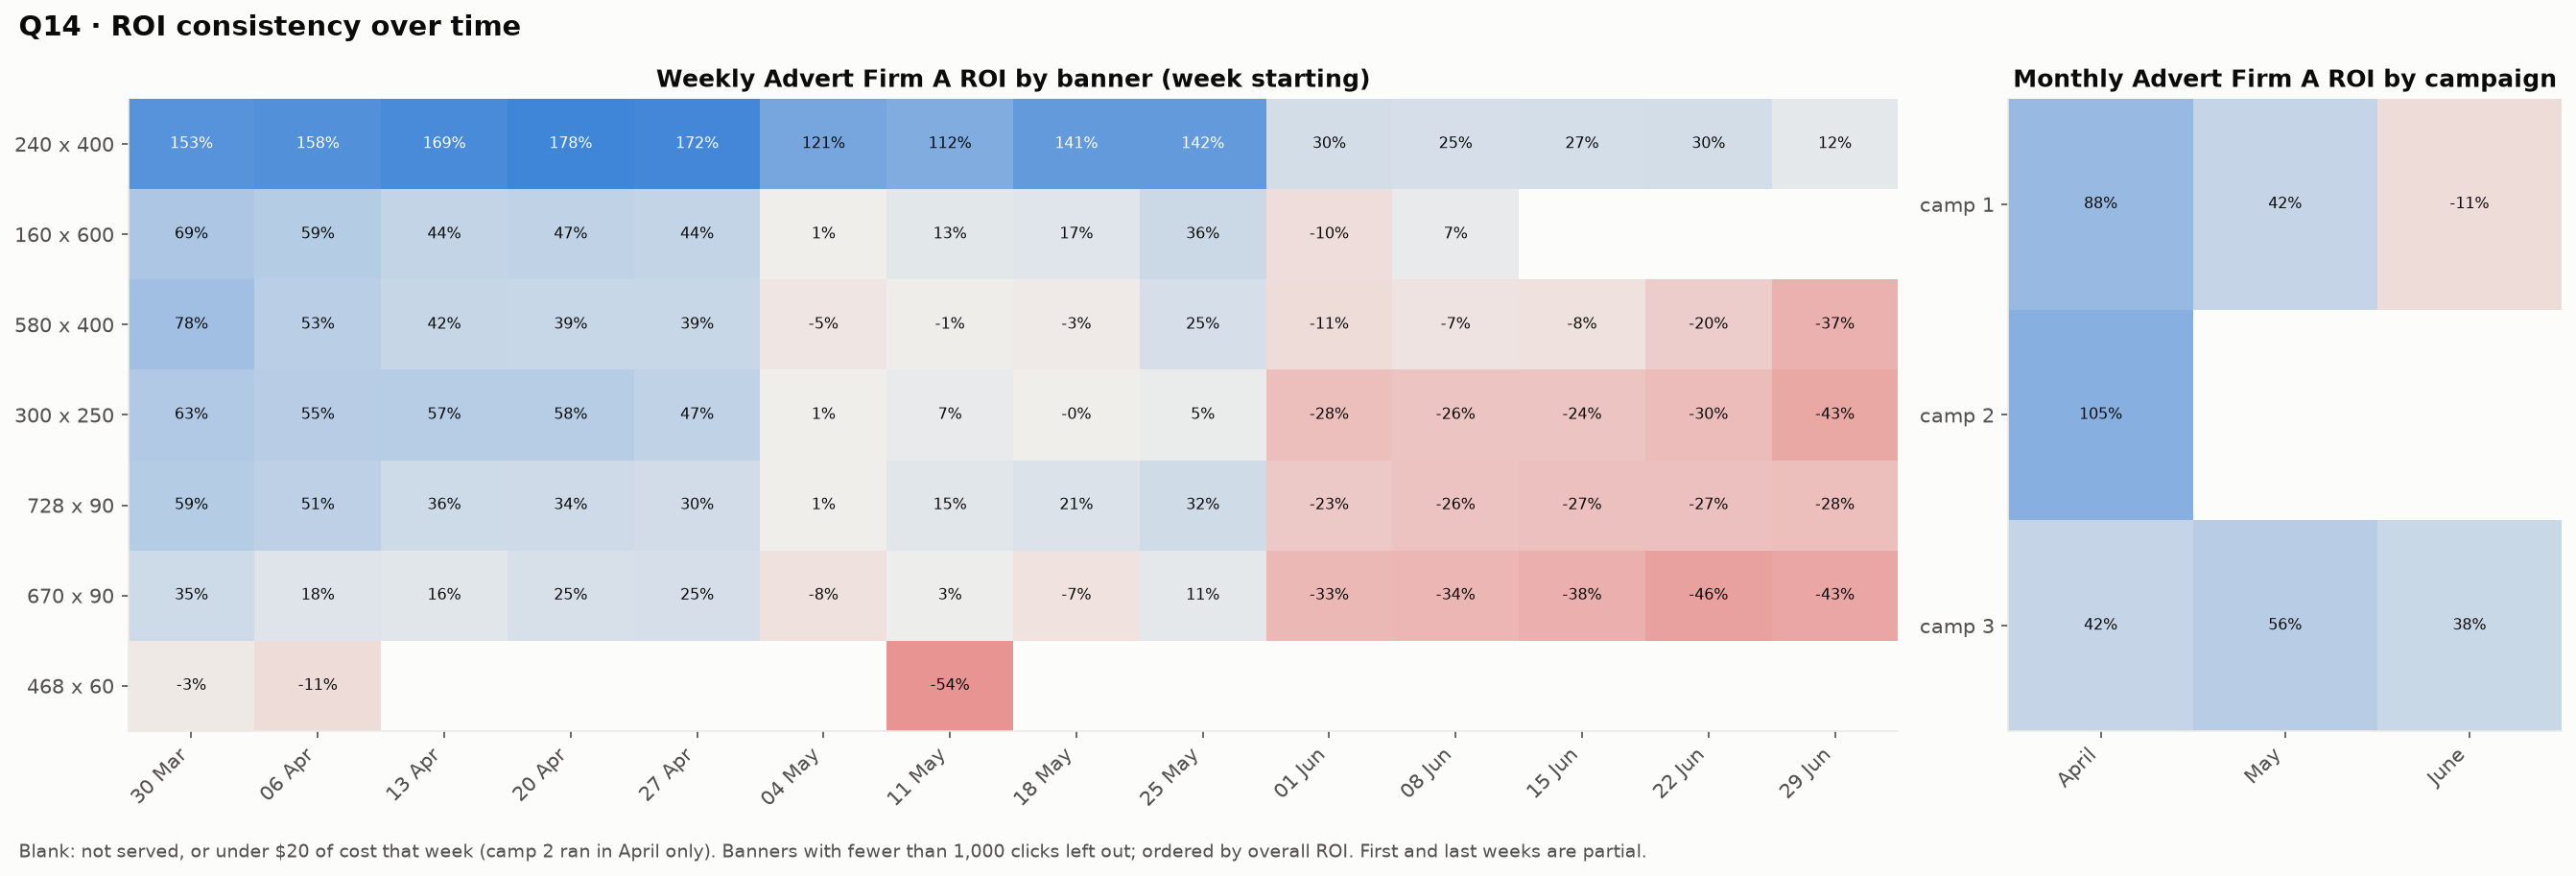

In [14]:
display(Image(filename=FIGURES / "18_roi_consistency.png", width=950))

### Computed findings

In [15]:
from analysis.insights import generate_insights

findings = generate_insights(df, PROJECT_ROOT / "reports")


BUSINESS INSIGHTS



EXECUTIVE SUMMARY
  1. Period 2020-04-01 to 2020-06-30: Company X paid $276,263; placements cost Advert Firm A $175,192 (firm ROI 58%).
  2. Activity declined steadily: avg daily revenue fell from $6,276 (first 14 days) to $887 (last 14 days); even excluding camp 2, April->June revenue changed -79%.
  3. Firm margin turned negative on 24 days, starting 2020-06-01.
  4. camp 1 generated 83% of revenue; camp 2 ran 2020-04-01 to 2020-04-30 only.
  5. Banner with highest CTR: 240 x 400; placement with highest CTR: ghi.
  6. Top banner×placement segment (240 x 400 @ ghi) produced 72% of total firm margin; 17 segments lost $4,782.
  7. Revenue is concentrated: top 1% of rows = 42%, top 10% = 89%.
  8. Cost vs revenue: Pearson r = 0.76, Spearman rho = 0.92 (strong monotonic link; Pearson is pulled down by skew).

  Findings saved: D:\VIT\Git Repo\finlatics-py\reports\eda_findings.json


In [16]:
# A few of the 20 official answers, straight from the computed findings
camps, f = findings["campaigns"], findings
pd.Series({
    "Q2  Banner with most clicks": f["banners"]["most_clicks"],
    "Q3  Placement with most displays / clicks":
        f"{f['placements']['most_displays']} / {f['placements']['most_clicks']}",
    "Q4  Cost vs revenue (Spearman)": round(f["relationships"]["cost~revenue"]["spearman"], 2),
    "Q5  Revenue per click": f"${f['revenue_per_click']['overall']:.3f}",
    "Q6  Campaign with highest conversion rate":
        max(camps, key=lambda c: camps[c]["conversion_rate"]),
    "Q9  Placement with highest conversion rate (≥1,000 clicks)":
        f["placement_conversions"]["highest_conversion_rate"],
    "Q11 Engagement vs revenue (Spearman, row level)":
        round(f["engagement_revenue"]["spearman_engagement_revenue"], 2),
    "Q14 Banners profitable every month": ", ".join(f["roi_consistency"]["banners_profitable_every_month"]),
    "Q18 Cheapest campaign per conversion":
        min(f["cost_per_conversion"]["by_campaign"], key=f["cost_per_conversion"]["by_campaign"].get),
}).to_frame("answer")

,answer
Q2 Banner with most clicks,240 x 400
Q3 Placement with most displays / clicks,mno / ghi
Q4 Cost vs revenue (Spearman),0.92
Q5 Revenue per click,$0.111
Q6 Campaign with highest conversion rate,camp 1
"Q9 Placement with highest conversion rate (≥1,000 clicks)",abc
"Q11 Engagement vs revenue (Spearman, row level)",0.2
Q14 Banners profitable every month,240 x 400
Q18 Cheapest campaign per conversion,camp 1


## 5. Machine learning

**Question:** *if Advert Firm A buys this inventory, how much revenue will it earn, and will it make a margin?*

- Target: `log1p(revenue)`; margin and profitability are derived from the prediction
- Inputs known **before** delivery only: campaign, engagement, banner, placement, weekday, day index, log(displays), log(cost)
- Split by **time**: train before 10 June 2020, test on 10–30 June

In [17]:
from models.feature_engineering import prepare_features, LEAKAGE_COLUMNS

data = prepare_features(df)
print("Never used as inputs:", LEAKAGE_COLUMNS)
data["X_train"].head()


FEATURE ENGINEERING



[1/3] Building pre-delivery features...
  Categorical (5): campaign_number, user_engagement, banner, placement, weekday
  Numeric (3): log_displays, log_cost, day_index
  Excluded as leakage (16): clicks, revenue, post_click_conversions, post_click_sales_amount, firm_margin, ctr, conversion_rate, firm_cpc, firm_roi, advertiser_cpc, advertiser_cpa, advertiser_roas, avg_order_value, flag_clicks_gt_displays, flag_conv_gt_clicks, flag_conv_without_clicks

[2/3] Target: log1p(revenue)
  Revenue skewness 12.8 -> log target skewness 1.7

[3/3] Time-based split at 2020-06-10...
  Train: 12,373 rows (2020-04-01 to 2020-06-09)
  Test:  3,030 rows (2020-06-10 to 2020-06-30)
Never used as inputs: ['clicks', 'revenue', 'post_click_conversions', 'post_click_sales_amount', 'firm_margin', 'ctr', 'conversion_rate', 'firm_cpc', 'firm_roi', 'advertiser_cpc', 'advertiser_cpa', 'advertiser_roas', 'avg_order_value', 'flag_clicks_gt_displays', 'flag_conv_gt_clicks', 'flag_conv_without_clicks']


,campaign_number,user_engagement,banner,placement,weekday,log_displays,log_cost,day_index
0,camp 1,High,160 x 600,abc,Wednesday,1.609438,0.005982,0.0
1,camp 1,High,160 x 600,def,Wednesday,9.912001,3.324403,0.0
2,camp 1,High,160 x 600,ghi,Wednesday,9.595739,3.354469,0.0
3,camp 1,High,160 x 600,mno,Wednesday,12.050938,5.383922,0.0
4,camp 1,Low,160 x 600,def,Wednesday,6.315358,0.064851,0.0


### Baselines (simple rate cards) vs the trained model

Training takes ~20 minutes (`python main.py`); here the saved model is evaluated live on the held-out period.

In [18]:
import numpy as np
from models.business_evaluation import (
    evaluate_predictions, global_rate_baseline, segment_rate_baseline,
)
from models.feature_engineering import target_to_revenue
from models import predictor

tr, te = data["eval_train"], data["eval_test"]
predictions = {
    "Baseline: global rate": global_rate_baseline(tr, te),
    "Baseline: segment rate (all history)": segment_rate_baseline(tr, te),
    "Baseline: segment rate (last 21 days)": segment_rate_baseline(tr, te, recent_days=21),
}
if predictor.model_available():
    name = predictor.get_metadata().get("best_model", "model")
    predictions[f"Model: {name}"] = target_to_revenue(predictor.load_model().predict(data["X_test"]))
else:
    print("No saved model: run `python main.py` to train it.")

rows = {}
for label, pred in predictions.items():
    r = evaluate_predictions(te, pred)
    rows[label] = {
        "R2 (log)": r["revenue"]["r2_log"],
        "MAE ($/row)": r["revenue"]["mae_usd"],
        "Total pred / actual": r["revenue"]["total_predicted_vs_actual"],
        "Profitable F1": r["profitability"]["f1"],
        "ROC-AUC": r["profitability"]["roc_auc"],
        "Margin captured ($)": r["margin"]["buy_predicted_profitable"],
    }
ref = r["margin"]
print(f"Buying everything: ${ref['buy_everything']:,.0f} | perfect foresight: ${ref['oracle']:,.0f}")
pd.DataFrame(rows).T.round(3)

Buying everything: $-1,798 | perfect foresight: $4,171


,R2 (log),MAE ($/row),Total pred / actual,Profitable F1,ROC-AUC,Margin captured ($)
Baseline: global rate,0.573,6.571,1.766,0.570,0.722,-359.968
Baseline: segment rate (all history),0.900,6.429,1.983,0.691,0.795,-1244.941
Baseline: segment rate (last 21 days),0.961,1.530,1.176,0.780,0.901,3974.861
Model: Gradient Boosting,0.965,0.924,0.980,0.787,0.903,4047.790


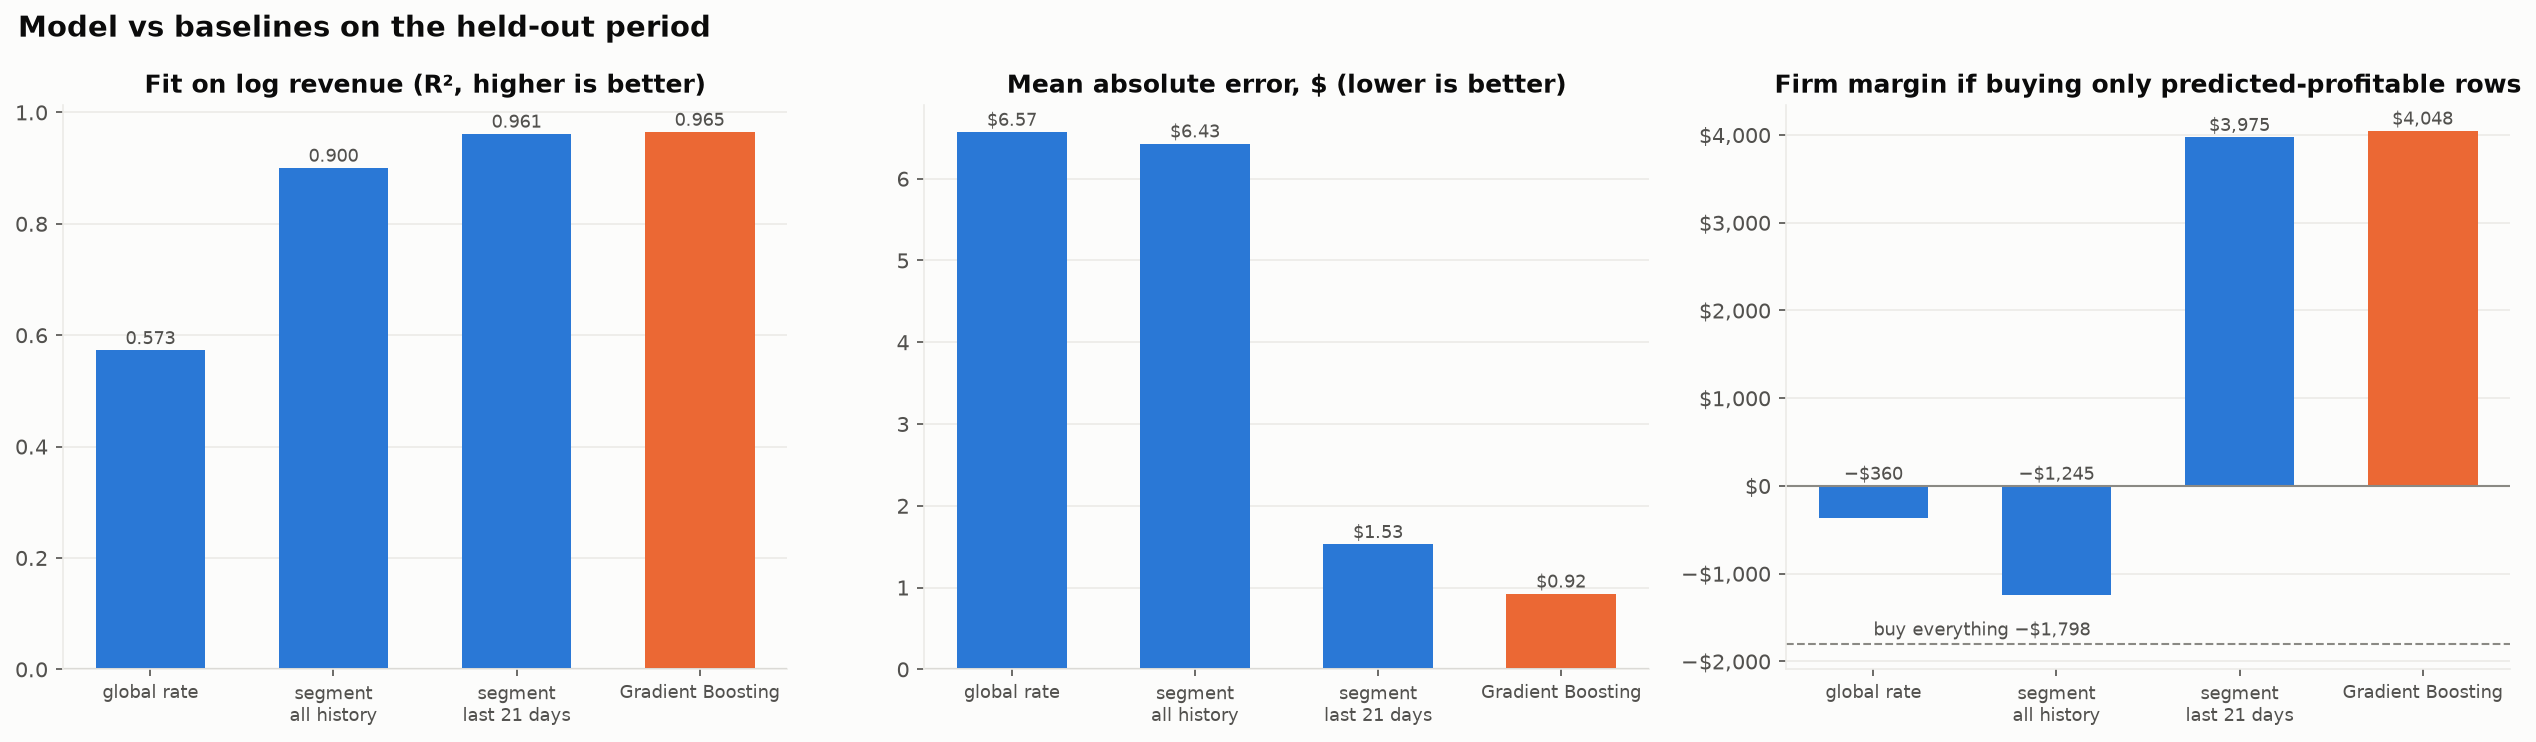

In [19]:
display(Image(filename=FIGURES / "ml" / "01_model_vs_baselines.png", width=950))

### Example: predicting a planned buy

In [20]:
if predictor.model_available():
    buy = {"date": "2020-06-20", "campaign_number": "camp 1", "user_engagement": "High",
           "banner": "240 x 400", "placement": "ghi", "displays": 30000, "cost": 20.0}
    assert predictor.validate_request(buy) == []
    display(pd.DataFrame(predictor.predict([buy])))

,predicted_revenue,cost,predicted_margin,predicted_roi,profitable,warnings
0,31.8043,20.0,11.8043,0.5902,True,[]


## 6. Conclusions

- **Activity declined all quarter.** Advert Firm A's margin turned negative in June. Post-click sales fell more slowly than ad spend, so Company X's ROAS rose.
- **Profit is concentrated.** One banner × placement combination (240×400 @ ghi) produced about 72% of the firm's margin, and 240×400 was the only banner profitable in every month. High-volume placement `mno` is barely profitable.
- **Engagement drives conversions.** Within each campaign, High-engagement users convert 4–27× better; Medium users click the most.
- **Revenue for a planned buy is highly predictable from scale and segment, but only if the trend is handled.** Rate cards based on all history over-predict June by about 2×.
- **Gradient boosting** gives the most accurate dollar forecasts. For simple profitable/not decisions, a recent rate card is nearly as good.

**Limitations:** three months of data from one advertiser; conversions use a post-click attribution window (correlation, not proven cause); no product costs, so Company X's profit can't be computed; tree models cannot extrapolate the time trend, so the model needs regular retraining.